# Reasoning Driving: `model_exploration.ipynb`

EGN 6216, Milestone 4: first model exploration (initial run and one targeted change).

The system asks a multimodal GPT model what one lane marking in a dash-cam photo allows a car to do. This notebook runs the first candidate on development images only, evaluates it, looks at its errors, makes one targeted change and compares the two runs on the same images with the same metrics.

### Summary

The first candidate is `gpt-6.1-sol` through the OpenAI Responses API with a strict JSON schema, given the image only (Test A). On 40 development images it got the marking type right for 40 of 40 images and all decided actions right for 36 of 37, with one unsafe error. The flaw I found is missing rule knowledge: it allowed crossing a single solid yellow line at the left edge of a divided road. The targeted change adds the 16 US rule passages to the prompt (Test B). This removed the unsafe error, but accuracy did not improve (35 of 37, exact McNemar p = 1.0). A second prompt version (v2) then removed the answers that contradict themselves and made the three repeats agree more often (90% and 97.5% of images). The full table is in Section 7.

| Section | Homework item |
|---|---|
| 1 | Role of AI, candidate approaches, the parts that are not AI, which stage first |
| 2 | Load and inspect the data; what was dropped or left unchanged; separation (6.5) |
| 3 | First candidate in its simplest form (Test A: image only); configuration recorded before tuning |
| 4 | Evaluation on the development images |
| 5 | Error inspection and practical constraints (latency, cost, readability, repeatability) |
| 6 | One targeted change: add the region's rule passages (Test B), same images, same metrics |
| 7 | Experiment table |
| 8 | Limitations, blockers, next steps |

How to run: Kernel > Restart Kernel and Run All Cells. The API key is read from `.env` (see the README). Runs are saved in `runs/<run_id>/`. If a finished run with the same settings, prompt, images and labels exists, it is reused, so running the notebook again costs nothing. The final test images are not used anywhere in this notebook.

## 0. Setup

In [1]:
import json, os, platform, subprocess, sys
from pathlib import Path

REPO = Path.cwd()
assert (REPO / "lane_reasoner").is_dir(), "Open this notebook from the repository folder."
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
import importlib
for m in [m for m in sys.modules if m.startswith("lane_reasoner")]:
    importlib.reload(sys.modules[m])

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

import lane_reasoner
from lane_reasoner import config as C, report as R
from lane_reasoner.data import load_items
from lane_reasoner.prompts import prompt_parts
from lane_reasoner.runner import ask, compare_runs, git_commit

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 72          # keeps the saved notebook small
try:
    get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
except NameError:
    pass
cfg = C.load(REPO)

# ---- the settings of this notebook -------------------------------------------------
REGION = "US"      # only US images are labeled so far; CN is configured and needs labels
SPLIT = "dev"      # development images only (Milestone 3, 6.5): the test set stays unused here
REPEATS = 3        # every image is asked 3 times: majority answer (requirement 6) and repeatability (2.1)
cfg["mock"] = False  # real API calls; finished runs with the same settings are reused instead of paid again
cfg["prompt"]["dir"] = "prompts/v1"   # runs 1-2; Section 6b repeats both tests with prompts/v2
cfg["api"]["reasoning_summary"] = None  # the Milestone 4 runs were made without a reasoning summary
# --------------------------------------------------------------------------------------

key = C.public(cfg)["api"]
assert cfg["mock"] or key["api_key_set"], "No API key: run Section 1 of experiment.ipynb once (it writes .env)."
print(f"Python {platform.python_version()} · lane_reasoner {lane_reasoner.__version__} · Git commit {git_commit(REPO) or '—'}")
print(f"Model {cfg['api']['model']} · reasoning_effort {cfg['api']['reasoning_effort']} · region {REGION} · split {SPLIT} · repeats {REPEATS}")
print(f"API key: {'set' if key['api_key_set'] else 'not set'}")

Python 3.11.18 · lane_reasoner 0.1 · Git commit d650e3c9c560
Model gpt-6.1-sol · reasoning_effort low · region US · split dev · repeats 3
API key: set


## 1. The role of AI, candidate approaches, and the parts that are not AI

What the AI does: the input is one dash-cam photo with the target marking framed by a cyan box, and the region where the photo was taken. The model (1) classifies the marking (type, arrow directions, position relative to the car) and (2) decides for six manoeuvres (cross the line, go straight, turn left, turn right, U-turn, enter a centre lane to wait) whether this marking allows them, prohibits them or does not govern them, or whether the photo does not show enough. It also rates how complete the visual evidence is, and when it gets rule passages, it names the passage it used. Input: image and region (plus rule passages in Test B). Output: one JSON object with a fixed schema.

Candidate approaches:

| Candidate | Fit for this task | Decision |
|---|---|---|
| A. Zero-shot multimodal LLM through the API (gpt-6.1-sol), structured JSON output, image only | Reads colour, pattern and arrows and reasons about what they allow; needs no training data (about 350 labeled images are planned, far too few to train); no GPU needed | First candidate (Test A) |
| B. Same model + the region's rule passages in the prompt (MUTCD or GB 5768.3) | This is the research question: does rule text help across regions? | The targeted change (Test B) |
| C. Few-shot: fixed text examples from development images (DiLu "memory") | May fix systematic misunderstandings | Later, after the development set covers both regions |
| D. Smaller, cheaper model (e.g. gpt-5.4-mini) | Lower cost; shows whether rule text matters more when the model knows less | Possible extra condition, to be decided before the test run |
| E. Open-weight vision-language model run locally | No GPU on the laptop; slow on CPU | Not practical |
| F. Lane detector (e.g. CULane-trained CNN) + hand-written rule table | Finds line geometry, but colour, type and region rules would have to be coded by hand, and training needs data I do not have | Not chosen; the rule table is used only to keep labels consistent |

Why A first: it is the simplest setup that produces both outputs, it fits the data (few labeled images, two regions) and the resources (a laptop and an API budget under $50), and the research question needs it as the baseline.

Which stage first: the system has five stages: keeping frames and labeling them, building the prompt, the model request, parsing, and scoring. I explored the model request first. It is the only stage whose behaviour is uncertain. The other stages are deterministic and are checked by the self-tests (36 and 32 checks), and the 40 final labels of the pilot drive were ready.

Parts that are not AI (each one is tested below or in the self-tests):
* Drawing the target box on a copy of the image (geometry); JPEG encoding.
* Choosing the rule passages of the photo's region (lookup by region code) and building the prompt from fixed templates.
* The JSON schema (strict mode) and the parser: an answer that does not match is counted as unreadable, not repaired.
* Scoring against the labels; contested rule-table cells are kept out of the main score (rule-table conventions, Milestone 3).
* The split rule (hash of the clip or drive), the dHash near-duplicate check, retries on rate limits, the answer cache.

In [2]:
# The self-tests check the non-AI stages on synthetic data with known answers, including invalid inputs:
# box drawing, prompt building (Test A has no rule text, Test B has exactly the region's passages), strict schema,
# parsing of malformed answers, scoring (perfect answer, unsafe error, made-up citation), exact McNemar test,
# retries on HTTP 429, a 400 error that names the parameter, incomplete answers, cache, and that the key is in no file.
for pkg in ("lane_reasoner", "video_tool"):
    r = subprocess.run([sys.executable, "-m", pkg, "selftest"], cwd=REPO, capture_output=True, text=True)
    lines = [l for l in r.stdout.splitlines() if l.startswith(("FAIL", "  FAIL"))]
    print(f"{pkg}: {r.stdout.strip().splitlines()[-1] if r.stdout.strip() else r.stderr[-500:]}" + ("\n" + "\n".join(lines) if lines else ""))

lane_reasoner: 36/36 checks passed
video_tool: 32/32 checks passed.


## 2. Load and inspect the data

The inputs are the final labels made with `video_tool` (two independent labels per image; I adjudicated the disagreements). Every label row of every workspace is read. A row is either used as it is or dropped, and nothing is filled in. Fields that are empty on purpose stay empty: `arrow_type` of a line, `dashed_side` of most markings, `accepted_rule_ids` of a marking no passage covers (e.g. a crosswalk), and actions marked `not_applicable` (they are not scored).

In [3]:
audit = R.data_audit(cfg)
display(Markdown(f"**Label rows used: {len(audit['used'])}** · dropped: {sum(audit['dropped'].values())}"))
display(pd.Series(audit["dropped"], name="rows dropped").to_frame() if audit["dropped"] else Markdown("Nothing dropped."))
used = pd.DataFrame(audit["used"])
display(used.groupby(["collection", "region", "split"]).size().rename("final labels").to_frame())
issues = pd.DataFrame(audit["issues"], columns=["image_id", "kind", "message"])
display(Markdown(f"**Label checker:** {int((issues.kind == 'error').sum()) if len(issues) else 0} errors, "
                 f"{int((issues.kind == 'warning').sum()) if len(issues) else 0} warnings"))
if len(issues):
    display(issues)

**Label rows used: 40** · dropped: 107

,rows dropped
not final yet (kept),103
not final yet (conflict),4


,,,final labels
collection,region,split,
own_video,US,dev,40


**Label checker:** 0 errors, 0 warnings

,date_utc,collection,drive_id,trips,from_split,to_split,labels_changed,reason
0,2026-10-27T02:16:23Z,own_video,fl_20261017_night_01,fl_20261017_night_01,test,dev,142,"Used to build, debug and demo the prompts and the scoring on 22 Oct 2026 (Test A/B answers and errors were inspected..."


**Development set used in this notebook: 40 images** (US, split `dev`)

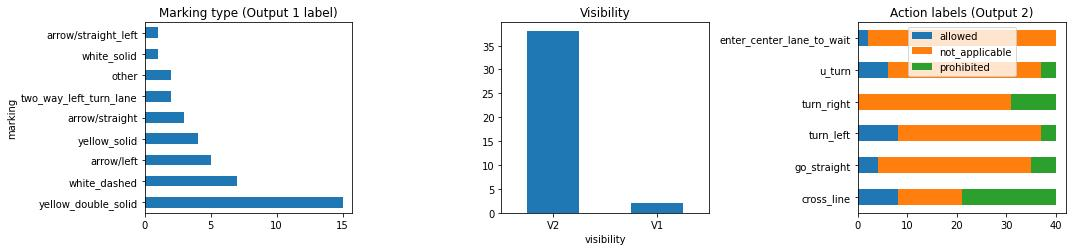

,,,images
collection,time_of_day,size,
own_video,night,1280×720,40


In [4]:
# Split changes recorded since Milestone 3 (labels/split_changes.csv), with the reason
chg = REPO / "labels" / "split_changes.csv"
display(pd.read_csv(chg) if chg.exists() else Markdown("No split change since Milestone 3 (labels/split_v1.csv)."))

items = load_items(cfg, REGION, SPLIT, [])
assert items, f"No final labels in the {SPLIT} split for {REGION}. Label development images first (see Section 8)."
dev = pd.DataFrame([{"image_id": i.image_id, "collection": i.collection, "split": i.split, "marking": i.marking,
                     "visibility": i.label.get("visibility"), "evidence": i.label.get("expected_evidence"),
                     "time_of_day": i.label.get("time_of_day"), "size": f"{i.width}×{i.height}"} for i in items])
display(Markdown(f"**Development set used in this notebook: {len(dev)} images** ({REGION}, split `{SPLIT}`)"))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
dev["marking"].value_counts().plot.barh(ax=axes[0], title="Marking type (Output 1 label)")
dev["visibility"].value_counts().plot.bar(ax=axes[1], title="Visibility", rot=0)
acts = pd.DataFrame([{a: i.label.get("act_" + a) for a in R.ACTIONS} for i in items])
acts.apply(lambda c: c.value_counts()).T.fillna(0).astype(int).plot.barh(stacked=True, ax=axes[2], title="Action labels (Output 2)")
fig.tight_layout(); plt.show()
display(dev.groupby(["collection", "time_of_day", "size"]).size().rename("images").to_frame())

### How certain the labels are, and how many clip-separated examples exist

The Milestone 3 feedback asked for usable counts per marking type and region, with the number of distinct clips, and for the label uncertainty. `video_tool combine` writes both with every split version: `labels/coverage_v<N>.csv` (final labels per region, split and type, distinct clips, how each label was reached) and `labels/candidate_supply.csv` (what BDD100K and CULane could still supply per pool and hint). Agreement between the two independent annotators is in `labels/own_video/agreement.csv`.

In [5]:
vers = sorted(int(p.stem.split("_v")[1]) for p in (REPO / "labels").glob("coverage_v*.csv"))
if vers:
    cov = pd.read_csv(REPO / "labels" / f"coverage_v{vers[-1]}.csv")
    display(Markdown(f"**Final labels per region, split and marking type** (`coverage_v{vers[-1]}.csv`)"))
    display(cov)
    display(Markdown(f"**Distinct clips: {cov.groupby(['region', 'split'])['clips'].max().to_dict()} (largest cell)** · every own-video label comes from one drive, so each type has 1 clip so far"))
agr = REPO / "labels" / "own_video" / "agreement.csv"
if agr.exists():
    display(Markdown("**Agreement of the two independent annotators** (own video, before adjudication)"))
    display(pd.read_csv(agr))
own = used[used.collection == "own_video"] if len(used) else used
if len(own):
    display(pd.Series({"final labels": len(own), "agreed by both annotators": int((own.final_source == "agreed").sum()),
                       "decided by adjudication": int((own.final_source == "adjudicated").sum()),
                       "not full evidence (V1 / partial)": int((own.expected_evidence != "full").sum())}, name="own video").to_frame())
sup = REPO / "labels" / "candidate_supply.csv"
if sup.exists():
    s = pd.read_csv(sup)
    display(Markdown("**What the datasets could still supply** (candidates and distinct clips; arrows: CULane category `cu_arrow`; BDD100K has no arrow label)"))
    display(s.pivot_table(index=["collection", "hint"], columns="pool", values=["images", "clips"], aggfunc="sum").fillna(0).astype(int))
chk = sorted((REPO / "labels").glob("split_check_v*.json"))
if chk:
    sc = json.loads(chk[-1].read_text(encoding="utf-8"))
    display(Markdown(f"**Saved separation check** (`{chk[-1].name}`): {len(sc['clips_on_both_sides'])} clips on both sides, "
                     f"{len(sc['near_duplicates_across_split'])} near-duplicate dev/test pairs (dHash ≤ {sc['max_bits']} bits) among {sc['images_hashed']} images, "
                     f"{len(sc['examples_not_from_dev'])} prompt examples not from development images, {len(sc['split_changes'])} recorded move(s)"))

**Final labels per region, split and marking type** (`coverage_v2.csv`)

,region,split,group,marking,images,clips,collections,agreed_by_two,adjudicated,single_label,not_full_evidence
0,US,dev,arrow,arrow/left,5,1,own_video,5,0,0,0
1,US,dev,arrow,arrow/straight,3,1,own_video,2,1,0,0
2,US,dev,arrow,arrow/straight_left,1,1,own_video,1,0,0,0
3,US,dev,dashed,white_dashed,7,1,own_video,7,0,0,0
4,US,dev,other,other,2,1,own_video,2,0,0,0
5,US,dev,solid,white_solid,1,1,own_video,1,0,0,0
6,US,dev,yellow,two_way_left_turn_lane,2,1,own_video,2,0,0,0
7,US,dev,yellow,yellow_double_solid,15,1,own_video,15,0,0,0
8,US,dev,yellow,yellow_solid,4,1,own_video,4,0,0,0


**Distinct clips: {('US', 'dev'): 1} (largest cell)** · every own-video label comes from one drive, so each type has 1 clip so far

**Agreement of the two independent annotators** (own video, before adjudication)

,field,items,percent_agreement,fleiss_kappa
0,marking_type,43,1.000,1.000
1,arrow_type,43,1.000,1.000
2,position,43,0.953,0.917
3,dashed_side,43,1.000,NaN
4,visibility,43,0.977,0.788
5,behavior_decidable,43,0.977,0.788
6,act_cross_line,43,0.977,0.964
7,act_go_straight,43,1.000,1.000
8,act_turn_left,43,0.977,0.947
9,act_turn_right,43,1.000,1.000


,own video
final labels,40
agreed by both annotators,39
decided by adjudication,1
not full evidence (V1 / partial),0


**What the datasets could still supply** (candidates and distinct clips; arrows: CULane category `cu_arrow`; BDD100K has no arrow label)

clips       images      
pool                             dev  test    dev  test
collection hint                                        
bdd100k    crosswalk             361  3264    361  3264
           no_lane               224  1890    224  1890
           white_dashed          516  4631    516  4631
           white_double_solid     39   328     39   328
           white_solid           497  4358    497  4358
           yellow_dashed          10    88     10    88
           yellow_double_solid   211  1846    211  1846
           yellow_solid          142  1181    142  1181
           yellow_solid_dashed    11   146     11   146
culane     cu_arrow               17   208     90   800
           cu_cross               20   219    364  2758
           cu_crowd               26   300    893  7220
           cu_curve                5    65     24   398
           cu_hlight               2    46      7   479
           cu_night                3    58    276  6753
           cu_noline              23   253    275  3792
           cu_normal              24   291    833  8788
           cu_shadow               7    88     43   887

**Saved separation check** (`split_check_v2.json`): 0 clips on both sides, 0 near-duplicate dev/test pairs (dHash ≤ 4 bits) among 40 images, 0 prompt examples not from development images, 1 recorded move(s)

Nothing is learned from the data, so there is no scaler, encoder or vocabulary to fit on a training split. The model is used as it is, and only the prompt is developed, on these development images (Milestone 3, 6.5).

Leakage checks (below): the prompt builder uses only the region, so every image of a region gets the same text plus the image itself. No label, note or image ID can reach the model. Every image used here is in the development split, and no clip or drive has images on both sides of the split. My own dash-cam video has never been public, so it cannot be in the model's pretraining data (BDD100K and CULane can be, see Milestone 3).

In [6]:
pa, pb = prompt_parts(cfg, "A", REGION), prompt_parts(cfg, "B", REGION)
leak = [f for f in ("image_id", "label_status", "accepted_rule_ids", "notes") if f in pa["instructions"] + pb["instructions"] + pa["user_text"]]
sep = R.check_separation(cfg, REGION, SPLIT, [])
print("label field names in the prompt:", leak or "none")
print("clips or drives on both sides of the split:", sep["clips on both sides of the split"] or "none", "· split version", sep["split version"])

label field names in the prompt: none
clips or drives on both sides of the split: none · split version 2


## 3. First candidate in its simplest working form: Test A (image only)

Default and documented settings, a simple zero-shot prompt (`prompts/v1`, no examples), one request per image and repeat. First one image end to end (the request without the image bytes, the raw answer, the parsed answer and its score), then the whole development set.

{
 "model": "gpt-6.1-sol",
 "input": [
  {
   "role": "developer",
   "content": [
    {
     "type": "input_text",
     "text": "You interpret road markings for a driving research project. You see one dash-camera photo and interpret ONE pavement marking: the marking inside the cyan rectangle.\n\n\"My car\" is the vehicle that took the photo; its hood may be visible at the bottom of the photo. Judge only the marking inside the cya \u2026 (full text in experiment.ipynb, Section 3)"
    }
   ]
  },
  {
   "role": "user",
   "content": [
    {
     "type": "input_text",
     "text": "This photo was taken in the United States. The cyan rectangle marks the target marking. Interpret it."
    },
    {
     "type": "input_image",
     "image_url": "<data:image/jpeg;base64,\u2026 208599 characters>",
     "detail": "high"
    }
   ]
  }
 ],
 "text": {
  "format": {
   "type": "json_schema",
   "name": "lane_marking_answer",
   "schema": "<strict JSON schema, see experiment.ipynb>",
   "strict":

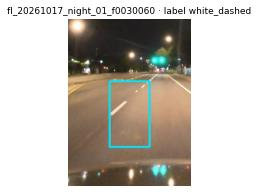

raw answer: {"description":"The rectangle contains a single broken white longitudinal line, with visible dashes and gaps, to the left of my car's lane.","evidence":"full","marking":{"marking_type":"white_dashed","arrow_type":null,"position":"left"},"actions":{"cross_line":"allowed","go_straight":"not_applicable","turn_left":"not_applicable","turn_right":"not_applicable","u_turn":"not_applicable","enter_center_lane_to_wait":"not_applicable"},"cited_rule_id":null,"reasoning":"In the United States, a broken white line separates lanes traveling in the same direction and permits crossing when safe. This marking allows a lane change across it but does not govern intersection turns or center-lane use."}
score: {'output1': True, 'output2': True, 'evidence_group': 'correct', 'unsafe': []}


In [7]:
from lane_reasoner.client import build_payload
from lane_reasoner.data import boxed_jpeg

it = items[0]
payload = build_payload(cfg, pa, boxed_jpeg(it, cfg))
img = payload["input"][1]["content"][1]
img["image_url"] = f"<data:image/jpeg;base64,… {len(img['image_url'])} characters>"
payload["input"][0]["content"][0]["text"] = payload["input"][0]["content"][0]["text"][:300] + " … (full text in experiment.ipynb, Section 3)"
payload["text"]["format"]["schema"] = "<strict JSON schema, see experiment.ipynb>"
print(json.dumps(payload, indent=1)[:2500])
plt.figure(figsize=(5, 3)); plt.imshow(R.crop(cfg, it.image_id, REGION)); plt.axis("off"); plt.title(f"{it.image_id} · label {it.marking}", fontsize=9); plt.show()
rec = ask(cfg, it, "A", 0, use_cache=True)
print("raw answer:", rec["text"] or rec["error"])
print("score:", {k: rec["score"][k] for k in ("output1", "output2", "evidence_group", "unsafe")} if rec["score"] else rec["parse_error"])

In [8]:
# Configuration recorded before any change (Milestone 4, section 3)
from lane_reasoner.client import settings_of
from lane_reasoner.runner import _label_hashes, split_version
before = {**settings_of(cfg), "prompt": f"{cfg['prompt']['dir']} (instructions {pa['hashes']['instructions']}, shared parts {pa['hashes']['shared_parts']})",
          "examples": "none (zero-shot)", "dataset version": _label_hashes(items), "split": f"{SPLIT} (v{split_version(cfg)})",
          "images": len(items), "repeats": REPEATS, "order seed": cfg["run"]["order_seed"],
          "sampling seed": "none: the API has no seed and gpt-6.1-sol takes no temperature, so variation is measured with repeats"}
display(pd.Series(before, name="Test A configuration").to_frame())

,Test A configuration
base_url,https://api.openai.com/v1
model,gpt-6.1-sol
reasoning_effort,low
temperature,None
image_detail,high
max_output_tokens,2000
instruction_role,developer
store,False
prompt,"prompts/v1 (instructions df7ad138ee9822e8, shared parts bb67091b0894ed80)"
examples,none (zero-shot)


In [9]:
run_a = R.find_or_run(cfg, "A", REGION, SPLIT, REPEATS)
display(pd.Series(R.config_record(cfg, run_a), name=run_a).to_frame())

Test A: reusing run 20261027_021643_testA_US (same settings, prompt, images, labels and repeats).


,20261027_021643_testA_US
run_id,20261027_021643_testA_US
date (UTC),2026-10-27T02:16:43Z
test,A (image only)
model requested,gpt-6.1-sol
model returned by the API,gpt-6.1-sol
API,https://api.openai.com/v1/responses (OpenAI Responses API)
reasoning_effort,low
temperature,not sent (the model does not accept it)
image_detail,high
max_output_tokens,2000


## 4. Evaluate the initial results

| Metric | Why |
|---|---|
| Output 2 exact match (main metric) | The system is about what the car may do. An image counts as correct only if every action the label decides is right; actions in contested rule-table cells are reported separately. |
| Unsafe errors | The costly mistake: the label prohibits an action and the model allows it. |
| Output 2 confusion matrix; precision, recall and F1 of *prohibited* | Each (image, action) pair the label decides is one classification. Recall of *prohibited* is the share of real prohibitions the model also calls prohibited (a miss is an unsafe or withheld answer). Precision is the share of the model's prohibitions that are real (a false one is over-caution). |
| Output 1 accuracy, per-class precision, recall and F1, macro-F1, confusion matrix | Classification of the marking; macro-F1 because the classes are unbalanced. |
| Evidence groups, readable answers, repeatability | Whether the model withholds an answer when it should (requirement 5), whether answers can be scored (target ≥ 95%), whether repeats agree (target ≥ 90%). |
| Hallucination indicators | *Confidently wrong* (evidence `full` but wrong); *inconsistent answers* (the answer contradicts itself, for example an action set for a marking that does not govern it, or `not_determined` with full evidence; checked without labels); *unsupported citations* (Test B cites a passage that does not support the answer, or an ID that does not exist). |

All scores use the majority answer of the repeats. With so few images, every number is preliminary.

,Test A
images,40
repeats,3
readable,1.0
output1_acc,1.0
output1_macro_f1,1.0
output2_acc,0.973
output2_correct,36
output2_n,37
unsafe_errors,1
over_cautious_errors,0


**Output 1 per class**

,support,precision,recall,f1
arrow/left,5.0,1.0,1.0,1.0
arrow/straight,3.0,1.0,1.0,1.0
arrow/straight_left,1.0,1.0,1.0,1.0
other,2.0,1.0,1.0,1.0
two_way_left_turn_lane,2.0,1.0,1.0,1.0
white_dashed,7.0,1.0,1.0,1.0
white_solid,1.0,1.0,1.0,1.0
yellow_double_solid,15.0,1.0,1.0,1.0
yellow_solid,4.0,1.0,1.0,1.0


**Confusion matrix (rows: label, columns: answer)**

answer,arrow/left,arrow/straight,arrow/straight_left,other,two_way_left_turn_lane,white_dashed,white_solid,yellow_double_solid,yellow_solid
label,,,,,,,,,
arrow/left,5,0,0,0,0,0,0,0,0
arrow/straight,0,3,0,0,0,0,0,0,0
arrow/straight_left,0,0,1,0,0,0,0,0,0
other,0,0,0,2,0,0,0,0,0
two_way_left_turn_lane,0,0,0,0,2,0,0,0,0
white_dashed,0,0,0,0,0,7,0,0,0
white_solid,0,0,0,0,0,0,1,0,0
yellow_double_solid,0,0,0,0,0,0,0,15,0
yellow_solid,0,0,0,0,0,0,0,0,4


**Evidence groups**

,images
correct,39
wrong,1


**Output 2 as a classification:** 60 (image, action) pairs the label decides, contested cells excluded. Rows: label, columns: answer

answer,allowed,prohibited
label,,
allowed,21,0
prohibited,1,38


,support (label),true positives,false positives,false negatives,precision,recall,f1
prohibited,39.0,38.0,0.0,1.0,1.000,0.974,0.987
allowed,21.0,21.0,1.0,0.0,0.955,1.000,0.977


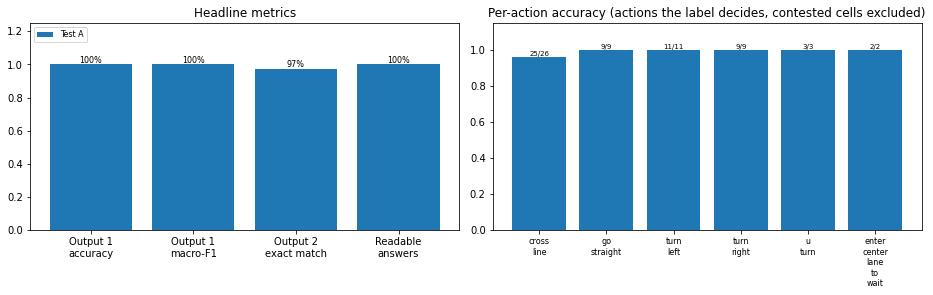

In [10]:
mA = R.metrics(cfg, run_a)
head = ["images", "repeats", "readable", "output1_acc", "output1_macro_f1", "output2_acc", "output2_correct", "output2_n",
        "unsafe_errors", "over_cautious_errors", "contested", "confidently_wrong", "inconsistent_answers", "unsupported_citations",
        "same_answer_all_repeats"]
display(pd.Series({k: mA[k] for k in head}, name="Test A").to_frame())
display(Markdown("**Output 1 per class**"))
display(pd.DataFrame(mA["output1_per_class"]).T.round(3))
display(Markdown("**Confusion matrix (rows: label, columns: answer)**"))
display(R.confusion(cfg, run_a))
display(Markdown("**Evidence groups**"))
display(pd.Series(mA["evidence_groups"], name="images").to_frame())
cmA, rowsA = R.action_confusion(cfg, run_a)
display(Markdown(f"**Output 2 as a classification:** {len(rowsA)} (image, action) pairs the label decides, contested cells excluded. Rows: label, columns: answer"))
display(cmA)
display(pd.DataFrame({c: R.class_prf(rowsA, c) for c in ("prohibited", "allowed")}).T)
R.plot_comparison({"Test A": mA}); plt.show()

## 5. Errors and practical constraints

Every image whose majority answer is wrong somewhere (Output 1, Output 2, an unsafe error, a contested cell, or the evidence level). The crops show the image as the model saw it, cut to the target box and the road around it.

**7 of 40 images have an error** (all inspected below)

,image,kinds,label,answer,evidence,differences (label / answer)
0,f0006600,"output 2, unsafe",yellow_solid,yellow_solid,full,cross_line: prohibited / allowed
1,f0008355,"contested cell, inconsistent: not_determined with full evidence",arrow/straight_left,arrow/straight_left,full,u_turn: allowed / not_determined
2,f0032775,"contested cell, inconsistent: not_determined with full evidence",arrow/left,arrow/left,full,u_turn: allowed / not_determined
3,f0032865,"contested cell, inconsistent: not_determined with full evidence",arrow/left,arrow/left,full,u_turn: allowed / not_determined
4,f0032940,"contested cell, inconsistent: not_determined with full evidence",arrow/left,arrow/left,full,u_turn: allowed / not_determined
5,f0039450,"inconsistent: two_way_left_turn_lane does not govern cross_line, go_straight, turn_right",two_way_left_turn_lane,two_way_left_turn_lane,full,cross_line: not_applicable / allowed; go_straight: not_applicable / prohibited; turn_right: not_applicable / prohibited
6,f0039465,"inconsistent: two_way_left_turn_lane does not govern go_straight, turn_right, u_turn",two_way_left_turn_lane,two_way_left_turn_lane,full,go_straight: not_applicable / prohibited; turn_right: not_applicable / prohibited; u_turn: not_applicable / not_dete...


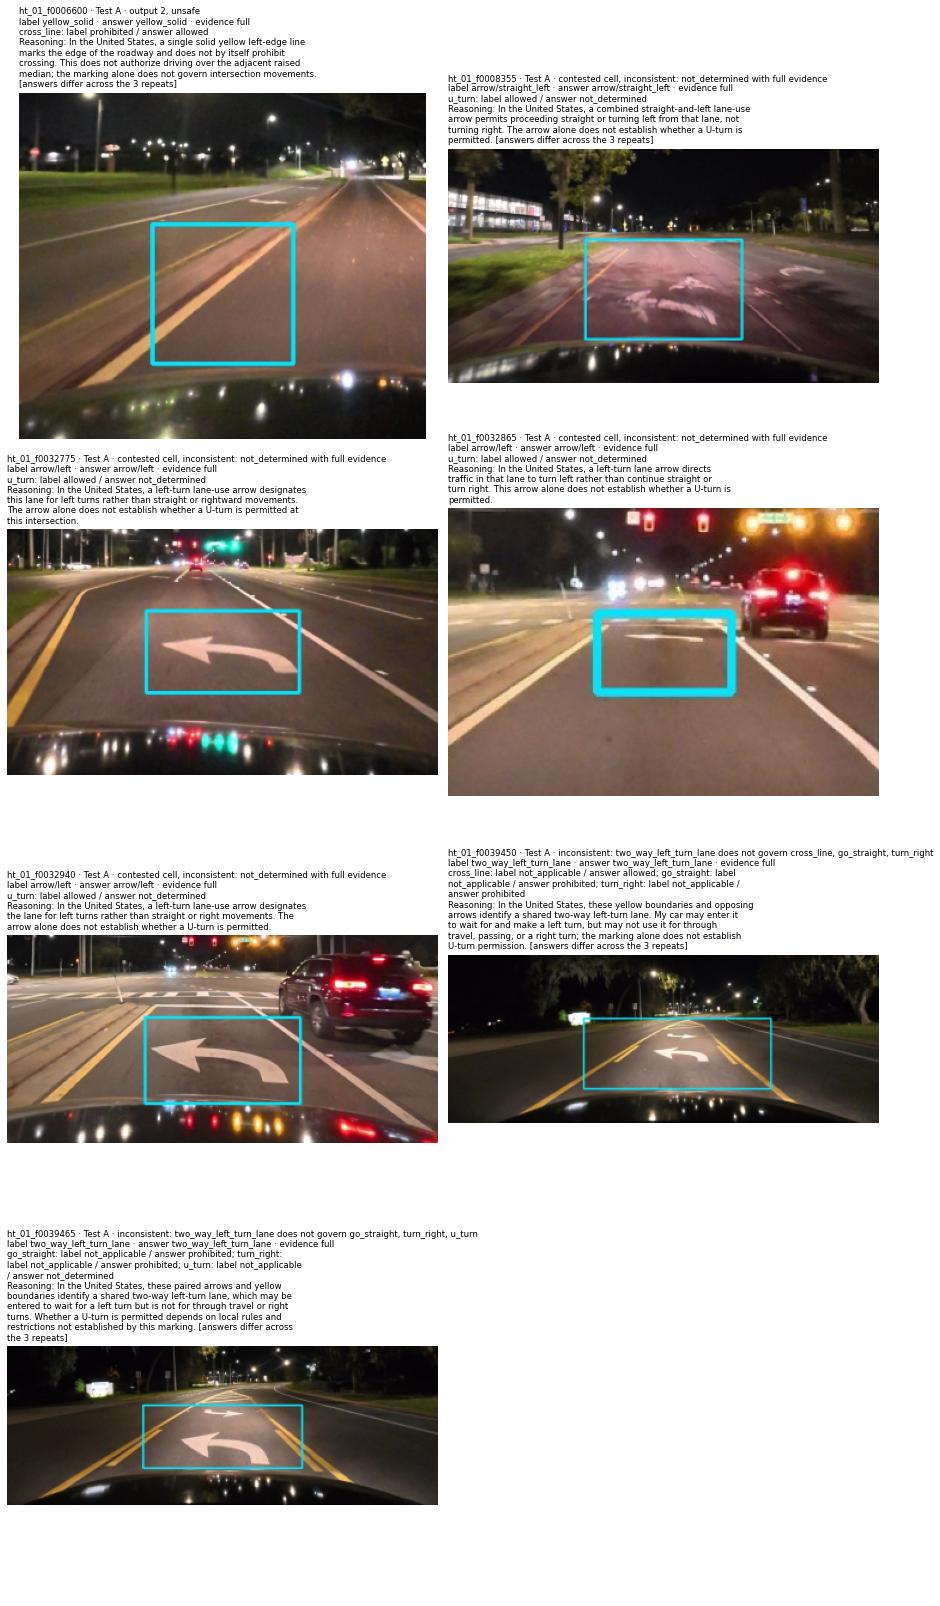

In [11]:
cases_a = R.error_cases(cfg, run_a)
display(Markdown(f"**{len(cases_a)} of {mA['images']} images have an error** (all inspected below)"))
display(pd.DataFrame([{"image": c["image_id"].split("_")[-1], "kinds": ", ".join(c["kinds"]), "label": c["label"], "answer": c["answer"],
                       "evidence": c["evidence"], "differences (label / answer)": "; ".join(f"{k}: {v[0]} / {v[1]}" for k, v in c["action_diffs"].items())}
                      for c in cases_a]))
R.show_cases(cfg, cases_a[:10], width=360); plt.show()

What the errors have in common (I looked at all 7 images with an error):
* All errors are about rules and the task definition. Output 1 is right for all 40 images, so the model sees the markings; it goes wrong on what a marking means or which actions it governs.
* One unsafe answer with evidence `full`: a single solid yellow line at the left edge of a divided road (f0006600). The model says crossing is allowed because "an edge line does not by itself prohibit crossing"; MUTCD 3B.09 ¶03 says it restricts driving to its left. The same answer comes back on another edge-line image (f0006510) in run 3, so it is a stable misconception that shows up on different images in different repeats.
* Six answers contradict the task definition (found by the consistency check, which needs no labels). For the two two-way left-turn lanes the model also rules on going straight, turning right and crossing, which such a lane does not govern. For four left-turn arrows it answers `not_determined` for the U-turn although it rates the evidence as `full`. The U-turn cell is contested (our convention says allowed), so it is reported separately and not in the main score.
* Repeatability is below the target: the three repeats agree on only 82.5% of the images (target ≥ 90%).

In [12]:
# Practical constraints, measured on this run, against the targets in Milestone 3, section 2.1
par = cfg["api"]["parallel"]
full_run_min = 600 * mA["latency_mean_s"] / par / 60 if mA["latency_mean_s"] else None   # 300 test images × 2 tests, 1 repeat
rows = [
    ("Readable answers", f"{mA['readable']:.0%}", "≥ 95%", mA["readable"] >= 0.95),
    ("Latency per request (mean / p50 / p95)", f"{mA['latency_mean_s']} / {mA['latency_p50_s']} / {mA['latency_p95_s']} s", "6 s assumed in 2.1", None),
    ("Full run (600 requests, parallel " + str(par) + ")", f"≈ {full_run_min:.0f} min" if full_run_min else "—", "< 60 min", (full_run_min or 99) < 60),
    ("Final comparison (1,800 requests: 3 repeats)", f"≈ {3 * full_run_min:.0f} min" if full_run_min else "—", "< 60 min", (3 * (full_run_min or 99)) < 60),
    ("Cost of the final comparison (estimate from this run)", f"≈ ${900 * mA['cost_per_request_usd'] + 900 * 0.0101:.0f}", "< $50 (2.5: about $28)", None),
    ("Cost per request (measured)", f"${mA['cost_per_request_usd']:.4f}", "$0.0084 estimated for Test A (2.5)", None),
    ("Cost of this run", f"${mA['cost_usd']:.2f} for {mA['requests']} requests", "total budget < $50", mA["cost_usd"] < 50),
    ("Same answer in all repeats", f"{mA['same_answer_all_repeats']:.0%}" if mA["same_answer_all_repeats"] is not None else "—", "≥ 90%",
     (mA["same_answer_all_repeats"] or 0) >= 0.9 if mA["same_answer_all_repeats"] is not None else None),
]
display(pd.DataFrame(rows, columns=["Constraint", "Measured", "Target (2.1 / 2.5)", "Met"]))
print(f"Conditions: laptop over Wi-Fi, OpenAI Responses API, {par} requests in parallel, model {cfg['api']['model']}, "
      f"tokens in/out {mA['input_tokens']}/{mA['output_tokens']}, cached answers not counted.")

,Constraint,Measured,Target (2.1 / 2.5),Met
0,Readable answers,100%,≥ 95%,True
1,Latency per request (mean / p50 / p95),4.83 / 4.41 / 7.33 s,6 s assumed in 2.1,None
2,"Full run (600 requests, parallel 5)",≈ 10 min,< 60 min,True
3,"Final comparison (1,800 requests: 3 repeats)",≈ 29 min,< 60 min,True
4,Cost of the final comparison (estimate from this run),≈ $15,< $50 (2.5: about $28),None
5,Cost per request (measured),$0.0064,$0.0084 estimated for Test A (2.5),None
6,Cost of this run,$0.51 for 120 requests,total budget < $50,True
7,Same answer in all repeats,82%,≥ 90%,False


Conditions: laptop over Wi-Fi, OpenAI Responses API, 5 requests in parallel, model gpt-6.1-sol, tokens in/out 168400/17360, cached answers not counted.


## 6. One targeted change: add the region's rule passages (Test B)

Why this change: the errors in Section 5 come from what a marking means in this region. Test B adds the region's rule passages (16 MUTCD passages for the US, each with its ID, section and page) to the instructions, changes step 2 from "recall the rules" to "find the passage below", and asks for the ID of the passage used.

Expected effect: fewer unsafe errors and a higher Output 2 score on markings that depend on the rules (edge lines, two-way left-turn lanes), and no change in Output 1. Everything else stays the same: images, repeats, model, settings, schema and user message.

In [13]:
only_b = [l for l in pb["instructions"].splitlines() if l not in set(pa["instructions"].splitlines())]
print("Lines only in Test B:", len(only_b))
print("\n".join(only_b[:12]) + "\n…")
print(f"\nShared parts identical: {pa['hashes']['shared_parts'] == pb['hashes']['shared_parts']}")
run_b = R.find_or_run(cfg, "B", REGION, SPLIT, REPEATS)
display(pd.Series(R.config_record(cfg, run_b), name=run_b).to_frame())

Lines only in Test B: 35
2. Find the rule passage below that applies to this marking (the passages are the traffic rules of the region where the photo was taken).
- cited_rule_id: the ID of the one passage below that best supports your answer, copied exactly as written in square brackets; null only if no passage applies.
RULE PASSAGES. Traffic rules of the United States: MUTCD 11th Edition (December 2023), Part 3 Markings. These are the only rules you may cite.
[US-3A.03-03-04] MUTCD 11th Edition (Dec 2023), Part 3, section 3A.03 ¶03–04, page 537
When used, yellow markings for longitudinal lines shall delineate: A. The separation of traffic traveling in opposite directions, B. The left-hand edge of the roadways of divided highways and one-way streets or ramps, or C. The separation of two-way left-turn lanes and reversible lanes from other lanes. When used, white markings for longitudinal lines shall delineate: A. The separation of traffic flows in the same direction, B. The right-hand 

,20261027_021740_testB_US
run_id,20261027_021740_testB_US
date (UTC),2026-10-27T02:17:40Z
test,B (image + rule passages)
model requested,gpt-6.1-sol
model returned by the API,gpt-6.1-sol
API,https://api.openai.com/v1/responses (OpenAI Responses API)
reasoning_effort,low
temperature,not sent (the model does not accept it)
image_detail,high
max_output_tokens,2000


,Test A,Test B
images,40,40
repeats,3,3
readable,1.0,1.0
output1_acc,1.0,0.975
output1_macro_f1,1.0,0.984
output2_acc,0.973,0.946
output2_correct,36,35
output2_n,37,37
unsafe_errors,1,0
over_cautious_errors,0,0


**Paired comparison on the same images** · same settings: True · same shared prompt parts: True

,images,Test A,Test B,only B right,only A right,exact McNemar p
output1,40.0,1.000,0.975,0.0,1.0,1.0
output2,37.0,0.973,0.946,1.0,2.0,1.0


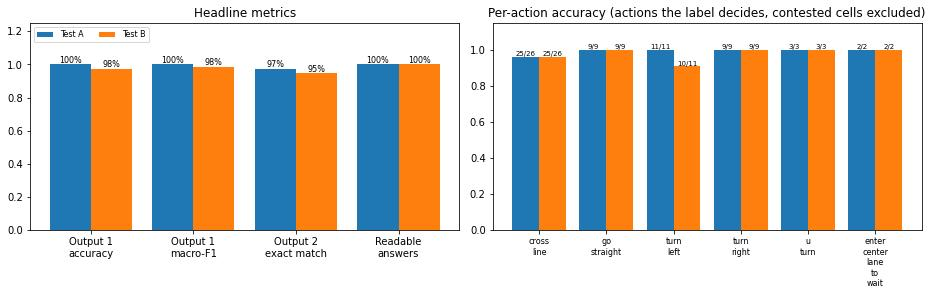

**Output 2 confusion matrix, Test B** (rows: label, columns: answer)

answer,allowed,not_applicable,not_determined,prohibited
label,,,,
allowed,20,1,0,0
prohibited,0,0,1,38


,support (label),true positives,false positives,false negatives,precision,recall,f1
class 'prohibited',,,,,,,
Test A,39.0,38.0,0.0,1.0,1.0,0.974,0.987
Test B,39.0,38.0,0.0,1.0,1.0,0.974,0.987


**Images where Test A and Test B answer differently**

,image,label,differences (A → B),A output 2,B output 2,A unsafe,B unsafe,B cited
0,fl_20261017_night_01_f0006600,yellow_solid,cross_line: allowed → prohibited (label prohibited),False,True,cross_line,,US-3B.09-03
1,fl_20261017_night_01_f0008355,arrow/straight_left,u_turn: not_determined → prohibited (label allowed),True,True,,,US-3B.23-01
2,fl_20261017_night_01_f0032685,arrow/left,u_turn: allowed → not_determined (label allowed),True,True,,,US-3B.23-01
3,fl_20261017_night_01_f0032775,arrow/left,u_turn: not_determined → prohibited (label allowed),True,True,,,US-3B.23-01
4,fl_20261017_night_01_f0032820,arrow/left,u_turn: allowed → not_determined (label allowed),True,True,,,US-3B.23-01
5,fl_20261017_night_01_f0032940,arrow/left,u_turn: not_determined → prohibited (label allowed),True,True,,,US-3B.23-01
6,fl_20261017_night_01_f0039450,two_way_left_turn_lane,u_turn: not_determined → not_applicable (label not_applicable),True,False,,,US-3B.05-01
7,fl_20261017_night_01_f0039465,two_way_left_turn_lane,cross_line: not_applicable → allowed (label not_applicable); u_turn: not_determined → not_applicable (label not_appl...,True,True,,,US-3B.05-01


**Citations in Test B:** {'accepted': 37, 'none': 1, 'none_needed': 2}

In [14]:
mB = R.metrics(cfg, run_b)
display(pd.DataFrame({"Test A": {k: mA[k] for k in head}, "Test B": {k: mB[k] for k in head}}))
c = compare_runs(cfg, run_a, run_b)
display(Markdown(f"**Paired comparison on the same images** · same settings: {c['same_settings']} · same shared prompt parts: {c['same_shared_prompt']}"))
display(pd.DataFrame({k: c[k] for k in ("output1", "output2")}).T.rename(columns={
    "n": "images", "acc_A": "Test A", "acc_B": "Test B", "only_B_right": "only B right", "only_A_right": "only A right", "p_value": "exact McNemar p"}))
R.plot_comparison({"Test A": mA, "Test B": mB}); plt.show()
cmB, rowsB = R.action_confusion(cfg, run_b)
display(Markdown("**Output 2 confusion matrix, Test B** (rows: label, columns: answer)"))
display(cmB)
display(pd.DataFrame({"Test A": R.class_prf(rowsA), "Test B": R.class_prf(rowsB)}).T.rename_axis("class 'prohibited'"))
display(Markdown("**Images where Test A and Test B answer differently**"))
display(R.paired_differences(cfg, run_a, run_b))
display(Markdown(f"**Citations in Test B:** {mB['citations']}"))

**Test B: 8 of 40 images have an error**

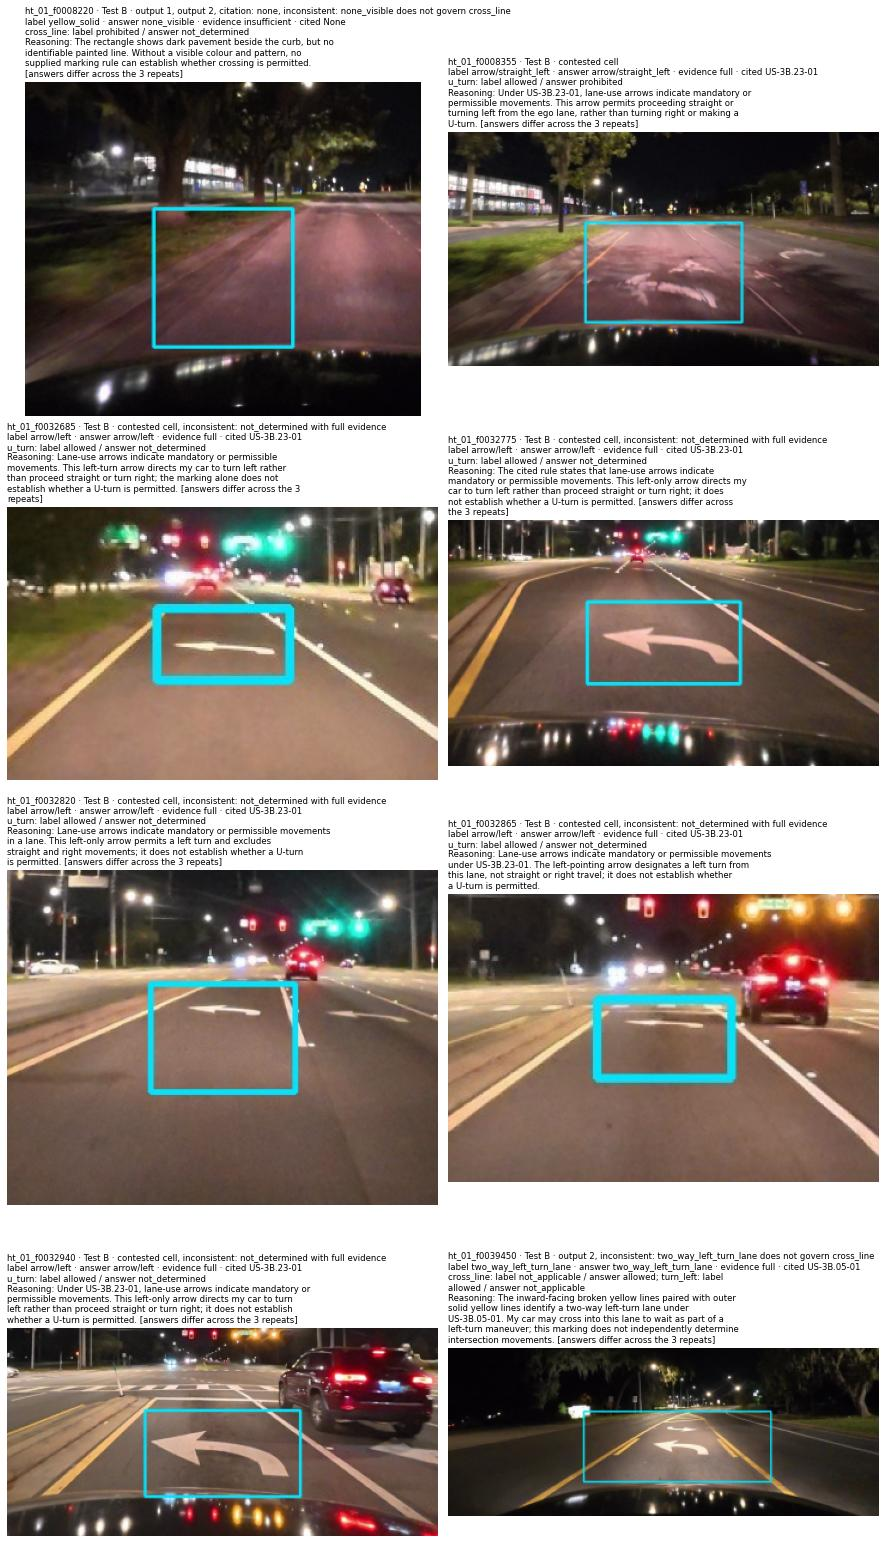

In [15]:
cases_b = R.error_cases(cfg, run_b)
display(Markdown(f"**Test B: {len(cases_b)} of {mB['images']} images have an error**"))
R.show_cases(cfg, cases_b[:10], width=360); plt.show()

Result of the change: the unsafe error went away, but accuracy did not improve.
* Unsafe errors went from 1 to 0. With the passages the model cites MUTCD 3B.09 ¶03 and prohibits crossing the yellow left edge line. This is the error type the change was aimed at.
* Output 2 went from 36/37 to 35/37 and Output 1 from 40 to 39. (a) On a two-way left-turn lane (f0039450) the model now calls turning left "not applicable", because v1 defines the movements "at the next intersection from the lane the arrow is in". The gap is in my task definition. (b) On a faint yellow edge line (f0008220) the majority answer calls it `none_visible` with insufficient evidence, but still answers `not_determined` for crossing instead of "not applicable", which contradicts itself. The three repeats also disagree on this image.
* Some problems stayed. The contested U-turn cell disagrees with the convention even more often (6 of 7: five `not_determined`, one `prohibited`), there are still 7 inconsistent answers, and repeatability stays low (80%).
* Only 3 images change between the tests, and the exact McNemar p is 1.0 for both outputs. With 40 easy images from one drive, in the region the model knows best, the development set cannot show a difference in accuracy. Only the safety-related change is visible.

## 6b. Second iteration (after the homework's one change): prompt v2 against unsupported answers

The errors of runs 1 and 2 led to prompt v2 (`prompts/v2/README.md`). It uses DiLu's reasoning and reflection ideas and is applied in the same way to Test A and Test B: describe only visible features before deciding; define which actions each marking class governs (including turning left out of a two-way left-turn lane); allow `not_determined` only with partial evidence; check the answer before writing it; in Test B, decide from the passages and not from memory. v2 adds no rules for any region and no examples. Images, repeats, model, settings and schema stay the same.

Test A: reusing run 20261027_021835_testA_US (same settings, prompt, images, labels and repeats).
Test B: reusing run 20261027_021957_testB_US (same settings, prompt, images, labels and repeats).


,A · v1,A · v2,B · v1,B · v2
images,40,40,40,40
repeats,3,3,3,3
readable,1.0,1.0,1.0,1.0
output1_acc,1.0,0.975,0.975,1.0
output1_macro_f1,1.0,0.984,0.984,1.0
output2_acc,0.973,0.946,0.946,0.973
output2_correct,36,35,35,36
output2_n,37,37,37,37
unsafe_errors,1,1,0,0
over_cautious_errors,0,0,0,0


**Test A: v1 → v2** · same settings True

,images,first,second,only second right,only first right,exact McNemar p
output1,40.0,1.000,0.975,0.0,1.0,1.0
output2,37.0,0.973,0.946,1.0,2.0,1.0


**Test B: v1 → v2** · same settings True

,images,first,second,only second right,only first right,exact McNemar p
output1,40.0,0.975,1.000,1.0,0.0,1.0
output2,37.0,0.946,0.973,1.0,0.0,1.0


**v2: Test A → Test B** · same settings True

,images,first,second,only second right,only first right,exact McNemar p
output1,40.0,0.975,1.000,1.0,0.0,1.0
output2,37.0,0.946,0.973,1.0,0.0,1.0


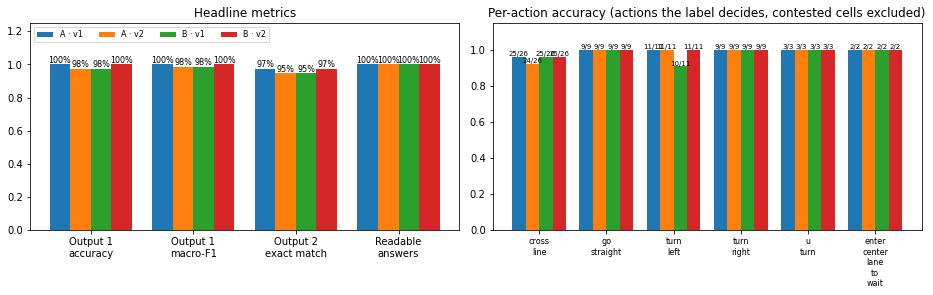

**Test B with v2: 7 of 40 images have an error**

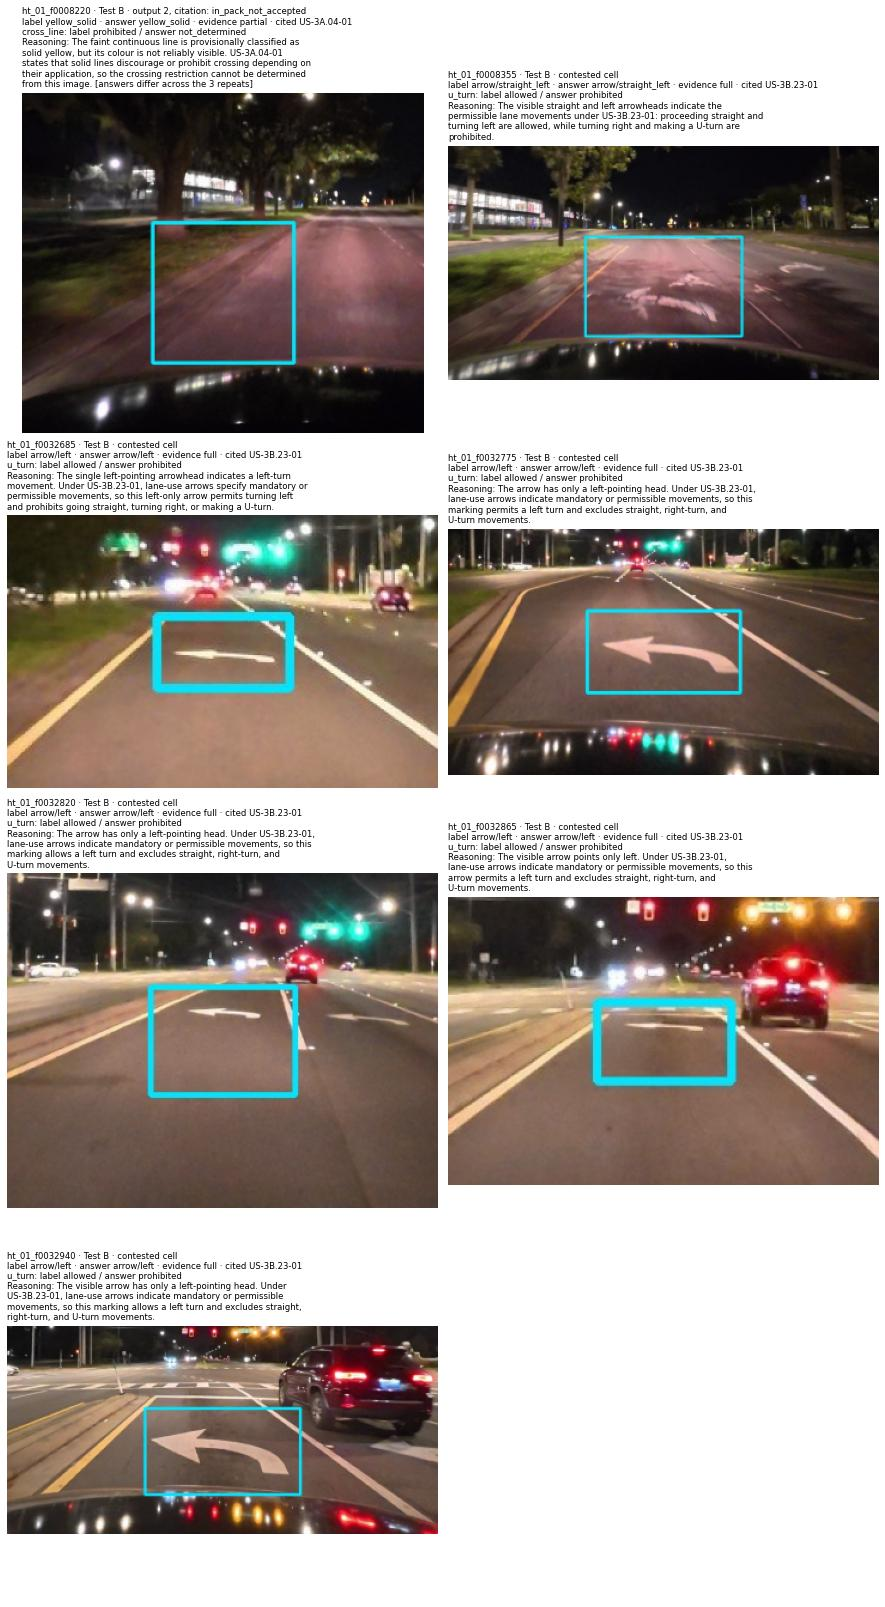

In [16]:
import copy
cfg2 = copy.deepcopy(cfg)
cfg2["prompt"]["dir"] = "prompts/v2"
run_a2 = R.find_or_run(cfg2, "A", REGION, SPLIT, REPEATS)
run_b2 = R.find_or_run(cfg2, "B", REGION, SPLIT, REPEATS)
mA2, mB2 = R.metrics(cfg2, run_a2), R.metrics(cfg2, run_b2)
display(pd.DataFrame({"A · v1": {k: mA[k] for k in head}, "A · v2": {k: mA2[k] for k in head},
                      "B · v1": {k: mB[k] for k in head}, "B · v2": {k: mB2[k] for k in head}}))
for name, (r1, r2) in {"Test A: v1 → v2": (run_a, run_a2), "Test B: v1 → v2": (run_b, run_b2), "v2: Test A → Test B": (run_a2, run_b2)}.items():
    c2 = compare_runs(cfg2, r1, r2)
    display(Markdown(f"**{name}** · same settings {c2['same_settings']}"))
    display(pd.DataFrame({k: c2[k] for k in ("output1", "output2")}).T.rename(columns={
        "n": "images", "acc_A": "first", "acc_B": "second", "only_B_right": "only second right", "only_A_right": "only first right", "p_value": "exact McNemar p"}))
R.plot_comparison({"A · v1": mA, "A · v2": mA2, "B · v1": mB, "B · v2": mB2}); plt.show()
cases_b2 = R.error_cases(cfg2, run_b2)
display(Markdown(f"**Test B with v2: {len(cases_b2)} of {mB2['images']} images have an error**"))
R.show_cases(cfg2, cases_b2[:10], width=360); plt.show()

What v2 changed:
* Contradictory answers are gone: inconsistent answers went from 6 to 0 (Test A) and from 7 to 0 (Test B). The two-way left-turn lanes are now answered only for what they govern, and `not_determined` no longer appears with full evidence.
* Answers are more stable: the three repeats agree on 90% (A) and 97.5% (B) of the images, up from 82.5% and 80%. Test B now meets the 90% target.
* Accuracy is the same within one image: Output 2 is 35/37 (A) and 36/37 (B). Test A still has one unsafe answer on a yellow edge line (f0006510 this time); Test B has none.
* Both tests now call the faint edge line (f0008220) hard to see (A: `insufficient`, B: `partial`, crossing `not_determined`). The label says the evidence is full, so this image goes to blind review as a possible label error. Test B cites 3A.04-01 (general functions of lines) here, which is not in the image's accepted list. This is the only unsupported citation.
* The rule text flips the contested U-turn cell. With v2, Test A answers `allowed` for all 7 (our convention) and Test B answers `prohibited` for 6 of 7, citing 3B.23-01 ("lane-use arrows indicate mandatory or permissible movements"). The passages do not settle U-turns, which is why the cell is contested; it also goes to blind review.
* Decision: v2 is the working prompt from now on. It is more stable, has no contradictions and has the same accuracy; each request costs about 5 to 8% more because the instructions are longer. It will be frozen only after development images from China are added.

## 7. Experiment table

In [17]:
table = R.experiment_table(cfg, [
    ("1 · initial", run_a, "— (gpt-6.1-sol, image only, prompts/v1, zero-shot)"),
    ("2 · targeted change", run_b, "add the region's rule passages (Test B); everything else fixed"),
]).pipe(lambda t: pd.concat([t, R.experiment_table(cfg2, [
    ("3 · second iteration", run_a2, "prompts/v2 (shared instructions), image only"),
    ("4 · second iteration", run_b2, "prompts/v2 + the region's rule passages"),
])], ignore_index=True))
display(table)
(REPO / "runs" / "milestone4_experiment_table.md").write_text(R.to_markdown(table) + "\n", encoding="utf-8")
print("Also saved as runs/milestone4_experiment_table.md (Markdown, for the submission).")

,Run,run_id,Configuration,Change,Images × repeats,Output 1 acc.,Output 1 macro-F1,Output 2 exact match,Unsafe errors,Inconsistent answers,Readable,Same answer in all repeats,Mean / p95 latency (s),Wall time (s),Cost (USD)
0,1 · initial,20261027_021643_testA_US,gpt-6.1-sol · effort low · A (image only) · v1,"— (gpt-6.1-sol, image only, prompts/v1, zero-shot)",40 × 3,1.000,1.000,36/37 (97.3%),1,6,1.0,0.825,4.83 / 7.33,49.8,0.5104
1,2 · targeted change,20261027_021740_testB_US,gpt-6.1-sol · effort low · B (image + rule passages) · v1,add the region's rule passages (Test B); everything else fixed,40 × 3,0.975,0.984,35/37 (94.6%),0,7,1.0,0.800,4.57 / 7.81,48.5,0.7687
2,3 · second iteration,20261027_021835_testA_US,gpt-6.1-sol · effort low · A (image only) · v2,"prompts/v2 (shared instructions), image only",40 × 3,0.975,0.984,35/37 (94.6%),1,0,1.0,0.900,4.78 / 7.99,74.7,0.8228
3,4 · second iteration,20261027_021957_testB_US,gpt-6.1-sol · effort low · B (image + rule passages) · v2,prompts/v2 + the region's rule passages,40 × 3,1.000,1.000,36/37 (97.3%),0,0,1.0,0.975,4.13 / 7.26,65.1,1.2178


Also saved as runs/milestone4_experiment_table.md (Markdown, for the submission).


## 8. Limitations, technical blockers and next steps

Limitations of this evaluation:
* The development set is small and narrow: one region (US), one drive, night only, every target fully visible. The scores are close to the ceiling, so Test A and Test B can hardly differ here. All numbers are preliminary.
* The action labels follow the rule-table conventions fixed in Milestone 3. Where a convention is contested (U-turn from a left-turn lane, crossing a single solid white line), the result is reported separately.

Data used and not used: only my own dash-cam video is sent to the API (`data.send_to_api` in `config/experiment.yaml`). BDD100K and CULane images will be sent only after their owners confirm in writing that this is allowed (README, *Data sent to the API*).

Technical blockers and what I did:
* `reasoning_effort: "none"` (the Milestone 3 plan) is rejected by gpt-6.1-sol (`HTTP 400 ... supported values are low, medium, high, xhigh, max`), so it is now `low`.
* `temperature` is not accepted by the model (`HTTP 400 unsupported parameter`), so it is not sent; answer variation is measured with three repeats instead.
* Reasoning tokens count toward the output limit, so `max_output_tokens` was raised from 400 to 2000 (only tokens used are paid).

Next steps:
1. Blind review (image, passages and two unnamed answers) of f0008220 (faint line: label error?) and of the contested U-turn cell; correct and log label errors, and report scores before and after.
2. Ask BDD100K and CULane for permission to send images to the API; then label development images for China (CULane development pool: 90 arrow frames in 17 clips) and for the US from BDD100K (each image its own clip), plus degraded images.
3. Record more own drives on different routes: US arrows come only from my own video (BDD100K has no arrow labels), and every own-video label so far is from one drive (one clip).
4. Freeze prompt v2 and the criteria (Git tag), label the test set and run it once (Milestone 3, 5.4 and 6.5).

External service and licences: OpenAI API (gpt-6.1-sol) under OpenAI's terms; requests are sent with `store: false`. BDD100K and CULane images keep their licences (CULane must not be redistributed). The crops above come from my own video.